# Exercise 1.3

## Classification of CIFAR10 images
### Optimizers
In this exercise we will classify the images from the CIFAR10 dataset. We will use different optimizers and compare their convergence speed. First we import the libraries that we need.

In [2]:
import numpy as np
from tqdm.notebook import tqdm
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.datasets as datasets
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

We always check that we are running on a GPU

In [3]:
if torch.cuda.is_available():
    device = torch.device('cuda')
    print("The code will run on GPU (CUDA).")
elif torch.backends.mps.is_available():
    device = torch.device('mps')
    print("The code will run on Apple GPU (MPS).")
else:
    device = torch.device('cpu')
    print("The code will run on CPU.")

The code will run on Apple GPU (MPS).


In this exercise we will classify images from the [CIFAR10](https://www.cs.toronto.edu/~kriz/cifar.html) dataset. 
CIFAR10 has 60000 colour images of size 32x32 equally distributed in 10 classes.
* You should load this dataset (hint: it is a built-in dataset in pytorch).

In [4]:
batch_size = 64

# add augmentation
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomCrop(32, padding = 4),  
    transforms.ToTensor(),
])  
test_transform = transforms.ToTensor()



trainset = datasets.CIFAR10(
    root='./data',train=True,download=True,transform=transforms.ToTensor()
)
train_loader = DataLoader(trainset, batch_size=batch_size, shuffle=True)
testset = datasets.CIFAR10(
    root='./data', train=False,download=True,transform=transforms.ToTensor()
)
test_loader = DataLoader(testset, batch_size=batch_size, shuffle=False)

print(f'Train images: {len(trainset)}, test images: {len(testset)}')

Train images: 50000, test images: 10000


* Make a CNN to train on the CIFAR10 dataset

In [14]:
class Network(nn.Module):
    def __init__(self):
        super(Network, self).__init__()
        #...
        self.convolutional = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
            # add batch normalization, question one
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), 

            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),             
        )

        self.fully_connected = nn.Sequential(
            # you can see, 4 is the output of the last maxpooling layer, original size is 32, it turns out to be 4 after 3 times of maxpooling  
            # 128 is the output of the last convolutional layer
            nn.Linear(4 * 4 * 128, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
            elif isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
                nn.init.zeros_(m.bias)
        
    def forward(self, x):
        #...
        x = self.convolutional(x)
        x = x.view(x.size(0),-1)
        x = self.fully_connected(x)
        # x = F.softmax(x, dim=1)
        return x

In [15]:
model = Network()
model.to(device)
#Initialize the optimizer
# optimizer = torch.optim.SGD(model.parameters(), lr=0.1) after trying to change the Lr
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

In [16]:
#We define the training as a function so we can easily re-use it.
def train(model, optimizer, num_epochs=10):
    def loss_fun(output, target):
        # return F.nll_loss(torch.log(output), target)
        return criterion(output, target) 
    out_dict = {'train_acc': [],
              'test_acc': [],
              'train_loss': [],
              'test_loss': []}
  
    for epoch in tqdm(range(num_epochs), unit='epoch'):
        model.train()
        #For each epoch
        train_correct = 0
        train_loss = []
        for minibatch_no, (data, target) in tqdm(enumerate(train_loader), total=len(train_loader)):
            data, target = data.to(device), target.to(device)
            #Zero the gradients computed for each weight
            optimizer.zero_grad()
            #Forward pass your image through the network
            output = model(data)
            #Compute the loss
            loss = loss_fun(output, target)
            #Backward pass through the network
            loss.backward()
            #Update the weights
            optimizer.step()

            train_loss.append(loss.item())
            #Compute how many were correctly classified
            predicted = output.argmax(1)
            train_correct += (target==predicted).sum().cpu().item()
        #Comput the test accuracy
        test_loss = []
        test_correct = 0
        model.eval()
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            with torch.no_grad():
                output = model(data)
            test_loss.append(loss_fun(output, target).cpu().item())
            predicted = output.argmax(1)
            test_correct += (target==predicted).sum().cpu().item()
        out_dict['train_acc'].append(train_correct/len(trainset))
        out_dict['test_acc'].append(test_correct/len(testset))
        out_dict['train_loss'].append(np.mean(train_loss))
        out_dict['test_loss'].append(np.mean(test_loss))
        print(f"Loss train: {np.mean(train_loss):.3f}\t test: {np.mean(test_loss):.3f}\t",
              f"Accuracy train: {out_dict['train_acc'][-1]*100:.1f}%\t test: {out_dict['test_acc'][-1]*100:.1f}%")
    return out_dict

 * Train the network and plot make a plot of the loss and accuracy for both training and with the epoch on the x-axis

  0%|          | 0/10 [00:00<?, ?epoch/s]

  0%|          | 0/782 [00:00<?, ?it/s]

Loss train: 1.291	 test: 1.146	 Accuracy train: 54.2%	 test: 59.5%


  0%|          | 0/782 [00:00<?, ?it/s]

Loss train: 0.909	 test: 0.978	 Accuracy train: 68.2%	 test: 66.1%


  0%|          | 0/782 [00:00<?, ?it/s]

... (11 outputs left out)

  0%|          | 0/782 [00:00<?, ?it/s]

Loss train: 0.345	 test: 0.868	 Accuracy train: 88.1%	 test: 73.7%


  0%|          | 0/782 [00:00<?, ?it/s]

Loss train: 0.302	 test: 0.967	 Accuracy train: 89.4%	 test: 72.2%


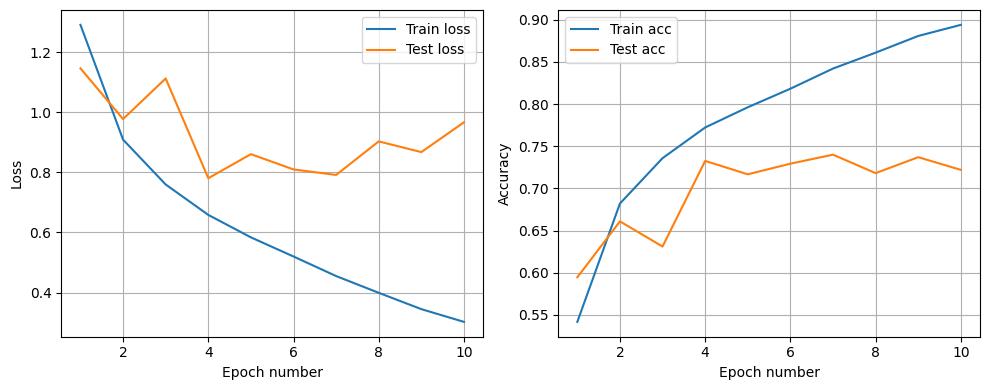

In [38]:
out_dict = train(model, optimizer)
# ...
# ...

epochs = range(1, len(out_dict['train_acc'])+1)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs, out_dict['train_loss'], label='Train loss')
plt.plot(epochs, out_dict['test_loss'], label='Test loss')
plt.xlabel('Epoch number')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.subplot(1, 2, 2)
plt.plot(epochs, out_dict['train_acc'], label='Train acc')
plt.plot(epochs, out_dict['test_acc'], label='Test acc')
plt.xlabel('Epoch number')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

* Discuss what you see. Are you overfitting to the training data? Do you not learn anything? What can you change to do better?

**Note: the methods of calculating train_acc and test **

```
    I can see the test accuracy rose from 39.5% at the beginning to around 68% at the end, with a peak of 69.5%. Meanwhile, the training accuracy increased steadily from 41.7% to 86.4%. Clearly, this is overfitting.

That said, the model does learn useful features compared with the no-loss softmax baseline.

For improvements: first, I will add data augmentation. Second, I will lower the learning rate. Then I’ll add BatchNorm and increase the number of epochs. 
```

* Repeat the above steps but using Adam as the optimizer. Use Pytorch's defaults parameters. Do you learn faster?
```
    yeah, got a better performance. 
    Line train acc:  54.8% to 90.1%
    Line test acc :  63.4% to 72%, obviously it's overfitting rn
```

* Which optimizer works best for you?

```
    Adam, learning rate = 1e-3
```


* Plot the test and test errors for both SGD and Adam in one plot
* Try adding Batch normalisation after your convolutional layers. Does it help?

```
    help a lot
```

**PERSONALLY : I WANNA ADD A AUGMENTATION TO HAVE A TRY, SEE WOULD IT BE BETTER :)**

```
 No differnce  
```

## ResNet

Now you will create and train a ResNet.
* Implement the Residual block as a network below using convolutional kernel size $3\times3$ according to the figure below
![Residual block](https://cdn-images-1.medium.com/max/800/1*D0F3UitQ2l5Q0Ak-tjEdJg.png)

In [5]:
class ResNetBlock(nn.Module):
    def __init__(self, n_features):
        super(ResNetBlock, self).__init__()
        # thinking: why input equals output in ResNet, but it's different in normal CNN
        self.conv1 = nn.Conv2d(n_features, n_features, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(n_features, n_features, kernel_size=3, padding=1)

    def forward(self, x):
        residual = x
        out = F.relu(self.conv1(x))
        out = self.conv2(out)
        out = F.relu(out + residual)
        return out


The following code is a sanity of your residual block network


`Conv2d` 的 **in 和 out 是通道数**（多少张特征图），不是图片的长宽。可以相同，也可以一层比一层多，都合法，用途不同。

```python
nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)
```

- **in**：上一层送来几张图  
- **out**：这一层要产出几张图（几个核）

## 为什么有的相同（残差块）

作业里的 `ResNetBlock`：

```python
Conv2d(n_features, n_features, ...)
```

因为最后要做 **`F(x) + x`**。相加要求两个张量形状完全一样，所以通道必须还是 `n_features`，高宽也用 `padding=1` 保持不变。

这叫 **在同一分辨率、同一通道数上加工**，不负责「变胖」或「缩小」。

## 为什么有的越来越大（你的普通 CNN）

热狗 / CIFAR 的直筒网：

```text
Conv2d(3, 32)    →  彩色 3 通道变成 32 种检测器
Conv2d(32, 64)   →  再变成 64 种
Conv2d(64, 128)  →  再变成 128 种
```

同时 **MaxPool 把高宽减半**。习惯是：

- 空间更小（细节位置变粗）  
- 通道更多（种类更多：边 → 纹理 → 物体零件）

第一层必须从 **3**（RGB）出发，不能一上来就 `Conv2d(128, 128)`，因为输入没有 128 个通道。

课程给的 `ResNet` 也是这样分工的：

```python
Conv2d(n_in, n_features, ...)   # 3 → 8：先把通道升到 8
ResNetBlock(n_features)         # 8 → 8：里面才能 +x
ResNetBlock(n_features)         # 还是 8 → 8
```

**变通道发生在块与块的交界 / 第一层；块内部为了 skip，通道不变。**

## 长宽 vs 通道（别混）

| | 谁在改 | 常见手段 |
|---|---|---|
| 高、宽 128→64→32 | 空间尺寸 | MaxPool、stride=2 的卷积 |
| 通道 3→32→64 | 特征图张数 | `out_channels` 写大一点 |

`padding=1` 的 3×3 卷积 **默认不改高宽**，只改（或不改）通道。

## 一句话

- **in=out**：同一套通道上精修，好做残差相加。  
- **out 比 in 大**：增加「检测器种类」，通常配着池化让图变小。  
数字不是算出来的唯一解，是结构选择；**残差相加处必须相等**，**第一层必须等于图像通道（CIFAR/热狗是 3）**。

In [6]:
#Sanity test of your implementation
C = 4
res_block = ResNetBlock(C)
assert(len(res_block.state_dict())==4)
for name, weight in res_block.state_dict().items():
    weight*=0
    desired_shape = {'bias': (C,), 'weight': (C, C, 3, 3)}[name.split('.')[-1]]
    assert(desired_shape==weight.shape)
x = torch.randn(32, C, 32,32)
assert(torch.abs(res_block(x)-F.relu(x)).max()==0)
print("Passed sanity check")

Passed sanity check


We define a network that uses your `ResNetBlock`

In [19]:
class ResNet(nn.Module):
    def __init__(self, n_in, n_features, num_res_blocks=3):
        super(ResNet, self).__init__()
        #First conv layers needs to output the desired number of features.
        conv_layers = [nn.Conv2d(n_in, n_features, kernel_size=3, stride=1, padding=1),
                       nn.ReLU()]
        for i in range(num_res_blocks):
            conv_layers.append(ResNetBlock(n_features))
        self.res_blocks = nn.Sequential(*conv_layers)
        self.fc = nn.Sequential(nn.Linear(32*32*n_features, 2048),
                                nn.ReLU(),
                                nn.Linear(2048, 512),
                                nn.ReLU(),
                                nn.Linear(512,10),
                                # nn.Softmax(dim=1)
        )
        
    def forward(self, x):
        x = self.res_blocks(x)
        #reshape x so it becomes flat, except for the first dimension (which is the minibatch)
        x = x.view(x.size(0), -1)
        out = self.fc(x)
        return out

Let's train our new ResNet!

In [20]:
model = ResNet(3, 8)
model.to(device)
#Initialize the optimizer
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)
out_dict = train(model, optimizer)

  0%|          | 0/10 [00:00<?, ?epoch/s]

  0%|          | 0/782 [00:00<?, ?it/s]

Loss train: 1.959	 test: 1.895	 Accuracy train: 29.5%	 test: 33.4%


  0%|          | 0/782 [00:00<?, ?it/s]

Loss train: 1.576	 test: 2.257	 Accuracy train: 43.8%	 test: 31.9%


  0%|          | 0/782 [00:00<?, ?it/s]

... (11 outputs left out)

  0%|          | 0/782 [00:00<?, ?it/s]

Loss train: 0.205	 test: 2.037	 Accuracy train: 93.0%	 test: 58.2%


  0%|          | 0/782 [00:00<?, ?it/s]

Loss train: 0.145	 test: 2.368	 Accuracy train: 95.2%	 test: 53.0%


## The reason why it's underfitting?
The ResNet is not overfitting: train and test accuracies stay close (~54% vs ~47%). It is underfitting / slow to converge—training accuracy is still low after 10 epochs. A likely reason is Softmax + CrossEntropy together; also n_features=8 is small.



Do you get nan loss at some point during training? 
This can be caused by the numerical instability of using softmax and log as two functions. 
* Change your network and loss to use a layer that combines the softmax log into one such as `nn.LogSoftmax`. You can also use `nn.CrossEntropyLoss` which also integrates `nn.NLLLoss`.